# DM1 09F — Interpretation of the independently selected clustering solution
# DM1 09F — 独立模型选择后的聚类解释

Notebook 09E independently selects the primary and baseline solutions and writes their assignments. This notebook then performs the complete interpretation workflow from top to bottom: input validation, bilingual taxonomy, confidence diagnostics, representative evidence, local split checks, community comparison, figures, and final exports. It does not call any external Python script.

09E 独立选择主要方案与基线方案并写出归属结果。本 Notebook 随后从上到下完成全部解释流程：输入验证、双语主题体系、置信度诊断、代表性证据、局部拆分检查、社区比较、图形与最终导出。它不调用任何外部 Python 脚本。


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_mutual_info_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path(r"D:\DM1_project")
INPUT_DIR = ROOT / "v2_clustering_outputs_09e_model_selection"
SOURCE_09C_DIR = ROOT / "v2_clustering_outputs_09c_review_informed"
OUTPUT_DIR = ROOT / "v2_clustering_outputs_09f_interpretation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ASSIGNMENT_PATH = INPUT_DIR / "09e_selected_assignments.parquet"
DECISION_PATH = INPUT_DIR / "final_selection_decision.json"
REVIEW_PACK_PATH = INPUT_DIR / "extended_candidate_interpretation_review_pack.csv"

print("Selected assignments:", ASSIGNMENT_PATH)
print("09E decision:", DECISION_PATH)
print("09F output:", OUTPUT_DIR)

Selected assignments: D:\DM1_project\v2_clustering_outputs_09e_model_selection\09e_selected_assignments.parquet
09E decision: D:\DM1_project\v2_clustering_outputs_09e_model_selection\final_selection_decision.json
09F output: D:\DM1_project\v2_clustering_outputs_09f_interpretation


## 1. Load and validate the final 09E solution / 读取并验证 09E 最终方案

The balanced modeling population remains 28,230 comments, with 4,705 comments from each of six communities. The equal-community design supports community comparisons but does not reproduce pooled Reddit prevalence.

建模样本仍为 28,230 条评论，六个社区各 4,705 条。等量抽样适合社区比较，但合并比例不代表 Reddit 的自然总体占比。

In [2]:
required_inputs = [ASSIGNMENT_PATH, DECISION_PATH, REVIEW_PACK_PATH, INPUT_DIR / "all_k_topic_terms.csv"]
missing_inputs = [str(path) for path in required_inputs if not path.exists()]
assert not missing_inputs, f"Missing 09E inputs: {missing_inputs}"

df = pd.read_parquet(ASSIGNMENT_PATH)
decision = json.loads(DECISION_PATH.read_text(encoding="utf-8"))

assert len(df) == 28_230
assert df["comment_id"].is_unique
assert df.groupby("subreddit").size().nunique() == 1
assert decision["status"] == "final_after_comparable_interpretation_review"
assert decision["primary_selection"] == {"method": "minilm_kmeans", "k": 9}
assert set(df["advanced_selected_cluster"].unique()) == set(range(9))
assert set(df["baseline_selected_cluster"].unique()) == set(range(11))

print("Rows:", f"{len(df):,}")
print(df.groupby("subreddit").size().to_string())
print("Primary:", decision["primary_selection"])
print("Baseline:", decision["baseline_selection"]["method"], "k=", decision["baseline_selection"]["k"])
print("Primary seed mean ARI:", round(decision["advanced_selection"]["metrics"]["mean_seed_ari"], 4))

selection_check = pd.DataFrame([
    {
        "role": "primary semantic model",
        "method": decision["advanced_selection"]["method"],
        "k": decision["advanced_selection"]["k"],
        "native_silhouette": decision["advanced_selection"]["metrics"]["silhouette_minilm"],
        "mean_seed_ari": decision["advanced_selection"]["metrics"]["mean_seed_ari"],
    },
    {
        "role": "lexical sensitivity baseline",
        "method": decision["baseline_selection"]["method"],
        "k": decision["baseline_selection"]["k"],
        "native_silhouette": decision["baseline_selection"]["metrics"]["silhouette_lsa"],
        "mean_seed_ari": decision["baseline_selection"]["metrics"]["mean_seed_ari"],
    },
])
display(selection_check.round(4))

Rows: 28,230
subreddit
Futurology       4705
changemyview     4705
climate          4705
climatechange    4705
conspiracy       4705
energy           4705
Primary: {'method': 'minilm_kmeans', 'k': 9}
Baseline: tfidf_lsa_kmeans k= 11
Primary seed mean ARI: 0.9752


,role,method,k,native_silhouette,mean_seed_ari
0,primary semantic model,minilm_kmeans,9,0.0705,0.9752
1,lexical sensitivity baseline,tfidf_lsa_kmeans,11,0.0984,0.8015


## 2. Define the reviewed bilingual taxonomy / 定义复核后的双语主题体系

Cluster numbers remain model outputs. Names and macro themes are interpretation fields based jointly on distinctive terms and equal-rule centroid/random samples from 09E. Broad labels are retained where comments span multiple closely related issues.

簇编号保持模型原始输出。主题名称和宏观主题依据区分性词语及 09E 的统一中心/随机样本共同确定；范围较宽的簇使用保守名称。

In [3]:
taxonomy_rows = [
    (0, "未来气候风险、适应与人类后果", "Future climate risk, adaptation, and human consequences",
     "公众认知与未来风险", "Public understanding and future risk", "broad",
     "涵盖适应能力、社会脆弱性、人口与未来后果", "Covers adaptive capacity, social vulnerability, population, and future consequences"),
    (1, "核能、核聚变与低碳电力", "Nuclear energy, fusion, and low-carbon power",
     "能源技术与基础设施", "Energy technologies and infrastructure", "clear",
     "核裂变、核聚变、反应堆成本与风险", "Nuclear fission, fusion, reactor costs, and risks"),
    (2, "气候信念、否认与公共传播", "Climate belief, denial, and public communication",
     "公众认知与未来风险", "Public understanding and future risk", "broad",
     "包含科学信任、否认叙事、传播和行动态度", "Includes scientific trust, denial narratives, communication, and attitudes toward action"),
    (3, "电动车与清洁交通", "Electric vehicles and clean transport",
     "能源技术与基础设施", "Energy technologies and infrastructure", "clear_with_noise",
     "以电动车、电池与充电为核心，含少量其他交通技术", "Centered on EVs, batteries, and charging, with minor other-transport content"),
    (4, "气候观测、天气变化与物理影响", "Climate observations, weather change, and physical impacts",
     "气候科学与物理影响", "Climate science and physical impacts", "clear_with_noise",
     "温度、冰、海洋、天气和模型证据，含少量归因争论", "Temperature, ice, oceans, weather, and model evidence, with minor attribution debate"),
    (5, "减排责任、消费与全球减缓行动", "Emission responsibility, consumption, and global mitigation",
     "减缓行动与碳管理", "Mitigation action and carbon management", "broad",
     "涵盖企业与个人责任、饮食、国家排放和减排政策", "Covers corporate and individual responsibility, food, national emissions, and mitigation policy"),
    (6, "可再生能源、电网与储能", "Renewables, grids, and storage",
     "能源技术与基础设施", "Energy technologies and infrastructure", "clear_with_noise",
     "风光、电网、储能与系统成本，含少量相邻发电技术", "Wind, solar, grids, storage, and system costs, with minor adjacent generation technologies"),
    (7, "化石燃料与转型政治经济", "Fossil fuels and transition political economy",
     "转型政治经济", "Transition political economy", "clear",
     "石油、天然气、煤炭、产业利益和转型政策", "Oil, gas, coal, industrial interests, and transition policy"),
    (8, "温室气体、碳循环与碳移除", "Greenhouse gases, carbon cycle, and carbon removal",
     "减缓行动与碳管理", "Mitigation action and carbon management", "clear",
     "CO2、甲烷、自然碳汇、碳捕集与移除", "CO2, methane, natural sinks, carbon capture, and removal"),
]

taxonomy = pd.DataFrame(taxonomy_rows, columns=[
    "primary_cluster", "topic_name", "topic_name_en",
    "macro_theme", "macro_theme_en", "interpretation_status",
    "interpretation_note", "interpretation_note_en",
])

df = df.merge(taxonomy, on="primary_cluster", how="left", validate="many_to_one")
assert df["topic_name"].notna().all()
taxonomy

,primary_cluster,topic_name,topic_name_en,macro_theme,macro_theme_en,interpretation_status,interpretation_note,interpretation_note_en
0,0,未来气候风险、适应与人类后果,"Future climate risk, adaptation, and human con...",公众认知与未来风险,Public understanding and future risk,broad,涵盖适应能力、社会脆弱性、人口与未来后果,"Covers adaptive capacity, social vulnerability..."
1,1,核能、核聚变与低碳电力,"Nuclear energy, fusion, and low-carbon power",能源技术与基础设施,Energy technologies and infrastructure,clear,核裂变、核聚变、反应堆成本与风险,"Nuclear fission, fusion, reactor costs, and risks"
2,2,气候信念、否认与公共传播,"Climate belief, denial, and public communication",公众认知与未来风险,Public understanding and future risk,broad,包含科学信任、否认叙事、传播和行动态度,"Includes scientific trust, denial narratives, ..."
3,3,电动车与清洁交通,Electric vehicles and clean transport,能源技术与基础设施,Energy technologies and infrastructure,clear_with_noise,以电动车、电池与充电为核心，含少量其他交通技术,"Centered on EVs, batteries, and charging, with..."
4,4,气候观测、天气变化与物理影响,"Climate observations, weather change, and phys...",气候科学与物理影响,Climate science and physical impacts,clear_with_noise,温度、冰、海洋、天气和模型证据，含少量归因争论,"Temperature, ice, oceans, weather, and model e..."
5,5,减排责任、消费与全球减缓行动,"Emission responsibility, consumption, and glob...",减缓行动与碳管理,Mitigation action and carbon management,broad,涵盖企业与个人责任、饮食、国家排放和减排政策,Covers corporate and individual responsibility...
6,6,可再生能源、电网与储能,"Renewables, grids, and storage",能源技术与基础设施,Energy technologies and infrastructure,clear_with_noise,风光、电网、储能与系统成本，含少量相邻发电技术,"Wind, solar, grids, storage, and system costs,..."
7,7,化石燃料与转型政治经济,Fossil fuels and transition political economy,转型政治经济,Transition political economy,clear,石油、天然气、煤炭、产业利益和转型政策,"Oil, gas, coal, industrial interests, and tran..."
8,8,温室气体、碳循环与碳移除,"Greenhouse gases, carbon cycle, and carbon rem...",减缓行动与碳管理,Mitigation action and carbon management,clear,CO2、甲烷、自然碳汇、碳捕集与移除,"CO2, methane, natural sinks, carbon capture, a..."


## 3. Assignment confidence / 聚类归属置信度

Membership strength is cosine similarity to the assigned MiniLM centroid. The same thresholds used in 09D are retained for comparability: high ≥ 0.60, medium 0.45–0.60, and low < 0.45. These bands indicate assignment confidence, not comment relevance.

成员强度是评论向量与所属 MiniLM 中心的余弦相似度。为保持可比性，沿用 09D 阈值：高置信度 ≥0.60，中等 0.45–0.60，低置信度 <0.45。它衡量聚类归属，不衡量评论是否相关。

In [4]:
df["confidence_band"] = pd.cut(
    df["primary_membership_strength"],
    bins=[-np.inf, 0.45, 0.60, np.inf],
    labels=["low", "medium", "high"],
    right=False,
)
p10 = df.groupby("primary_cluster")["primary_membership_strength"].quantile(0.10)
df["within_cluster_bottom_10pct"] = (
    df["primary_membership_strength"] < df["primary_cluster"].map(p10)
)

confidence_pct = (
    pd.crosstab(df["primary_cluster"], df["confidence_band"], normalize="index")
    .mul(100).reindex(columns=["high", "medium", "low"], fill_value=0).reset_index()
)
confidence_pct.columns = ["primary_cluster", "high_conf_pct", "medium_conf_pct", "low_conf_pct"]
confidence_pct.round(1)

,primary_cluster,high_conf_pct,medium_conf_pct,low_conf_pct
0,0,71.0,22.2,6.8
1,1,76.2,19.1,4.6
2,2,70.7,22.0,7.2
3,3,66.8,26.1,7.1
4,4,50.2,35.1,14.7
5,5,64.9,27.6,7.5
6,6,68.1,25.6,6.4
7,7,53.0,33.6,13.4
8,8,69.0,24.8,6.2


## 4. Distinctive terms and comparable reading evidence / 区分性词语与统一阅读证据

09E calculated class-based TF-IDF terms for every method and k using the same cleaned comment text. The 09F terms are therefore selected without changing the representation or vocabulary after model choice. The interpretation sample contains three centroid-nearest and three random comments per topic.

09E 已使用同一清洗评论文本为所有方法和 k 计算 class-based TF-IDF。09F 直接读取 k=9 的结果，不在选模后改变词表。解释样本每个主题包含 3 条中心评论和 3 条随机评论。

In [5]:
all_terms = pd.read_csv(INPUT_DIR / "all_k_topic_terms.csv")
distinctive_terms = all_terms.loc[
    all_terms["method"].eq("minilm_kmeans") & all_terms["k"].eq(9)
].rename(columns={"cluster": "primary_cluster"}).copy()
distinctive_wide = (
    distinctive_terms.groupby("primary_cluster")["term"]
    .apply(lambda x: ", ".join(x)).rename("distinctive_terms").reset_index()
)

review_sample = pd.read_csv(REVIEW_PACK_PATH)
review_sample = review_sample.loc[
    review_sample["method"].eq("minilm_kmeans") & review_sample["k"].eq(9)
].rename(columns={"cluster": "primary_cluster"}).copy()
review_sample = review_sample.merge(
    taxonomy[["primary_cluster", "topic_name", "topic_name_en"]],
    on="primary_cluster", how="left", validate="many_to_one",
)

display(distinctive_wide.merge(
    taxonomy[["primary_cluster", "topic_name", "topic_name_en"]],
    on="primary_cluster",
))
print("Interpretation review rows:", len(review_sample))

,primary_cluster,distinctive_terms,topic_name,topic_name_en
0,0,"planet, life, humans, earth, future, populatio...",未来气候风险、适应与人类后果,"Future climate risk, adaptation, and human con..."
1,1,"nuclear, power, energy, fusion, reactors, plan...",核能、核聚变与低碳电力,"Nuclear energy, fusion, and low-carbon power"
2,2,"science, real, warming, believe, scientists, r...",气候信念、否认与公共传播,"Climate belief, denial, and public communication"
3,3,"ev, car, electric, vehicles, battery, batterie...",电动车与清洁交通,Electric vehicles and clean transport
4,4,"temperature, warming, weather, ice, data, wate...",气候观测、天气变化与物理影响,"Climate observations, weather change, and phys..."
5,5,"emissions, carbon, china, meat, energy, countr...",减排责任、消费与全球减缓行动,"Emission responsibility, consumption, and glob..."
6,6,"solar, energy, power, wind, grid, electricity,...",可再生能源、电网与储能,"Renewables, grids, and storage"
7,7,"oil, energy, fossil, gas, trump, coal, fuels, ...",化石燃料与转型政治经济,Fossil fuels and transition political economy
8,8,"co2, carbon, atmosphere, methane, emissions, c...",温室气体、碳循环与碳移除,"Greenhouse gases, carbon cycle, and carbon rem..."


Interpretation review rows: 54


## 5. Final topic profiles and representative comments / 最终主题画像与代表评论

Profiles combine size, assignment confidence, source concentration, review-gate score, direct-comment evidence, and distinctive terms. Representative comments are drawn from high-confidence rows and distinct posts.

主题画像综合规模、归属置信度、来源集中度、复核门控分数、评论自身证据和区分性词语。代表评论只从高置信度且不同帖子中抽取。

In [6]:
cluster_base = (
    df.groupby("primary_cluster")
    .agg(
        size=("comment_id", "size"),
        mean_membership=("primary_membership_strength", "mean"),
        median_membership=("primary_membership_strength", "median"),
        p10_membership=("primary_membership_strength", lambda x: x.quantile(0.10)),
        mean_review_gate_score=("review_gate_score", "mean"),
        direct_comment_share=("direct_comment", "mean"),
    ).reset_index()
)
cluster_base["sample_share_pct"] = cluster_base["size"] / len(df) * 100

source_share = df.groupby(["primary_cluster", "subreddit"]).size().rename("n").reset_index()
source_share["share"] = source_share["n"] / source_share.groupby("primary_cluster")["n"].transform("sum")
largest_source = source_share.loc[source_share.groupby("primary_cluster")["share"].idxmax()]
largest_source = largest_source[["primary_cluster", "subreddit", "share"]].rename(
    columns={"subreddit": "largest_subreddit", "share": "largest_subreddit_share"}
)

profiles = (
    taxonomy.merge(cluster_base, on="primary_cluster")
    .merge(confidence_pct, on="primary_cluster")
    .merge(largest_source, on="primary_cluster")
    .merge(distinctive_wide, on="primary_cluster")
)
profiles["reporting_treatment"] = profiles["interpretation_status"].map({
    "clear": "独立报告",
    "clear_with_noise": "独立报告并注明少量边界内容",
    "broad": "保留宽泛名称并避免过度细分",
})
profiles["reporting_treatment_en"] = profiles["interpretation_status"].map({
    "clear": "Report as a standalone topic",
    "clear_with_noise": "Report as a standalone topic with a minor boundary caveat",
    "broad": "Retain a broad label and avoid over-fragmentation",
})

example_rows = []
for cluster, group in df.loc[df["confidence_band"].eq("high")].groupby("primary_cluster"):
    chosen = (
        group.sort_values("primary_membership_strength", ascending=False)
        .drop_duplicates("post_id").head(5)
    )
    for rank, row in enumerate(chosen.itertuples(index=False), start=1):
        example_rows.append({
            "primary_cluster": int(cluster), "rank": rank,
            "comment_id": row.comment_id, "subreddit": row.subreddit,
            "post_title": row.post_title,
            "comment_excerpt": " ".join(str(row.clean_text).split())[:500],
            "membership_strength": row.primary_membership_strength,
            "review_gate_score": row.review_gate_score,
        })
representative_examples = pd.DataFrame(example_rows).merge(
    taxonomy[["primary_cluster", "topic_name", "topic_name_en", "macro_theme", "macro_theme_en"]],
    on="primary_cluster", how="left",
)

display(profiles[[
    "primary_cluster", "topic_name", "size", "sample_share_pct", "mean_membership",
    "high_conf_pct", "low_conf_pct", "largest_subreddit", "largest_subreddit_share",
    "interpretation_status", "distinctive_terms",
]].round(3))

# One-row-per-topic evidence table: this is the compact basis used to judge and name topics.
topic_judgment_basis = profiles[[
    "primary_cluster", "size", "sample_share_pct", "distinctive_terms",
    "topic_name", "topic_name_en", "macro_theme", "macro_theme_en",
    "interpretation_status", "interpretation_note", "interpretation_note_en",
    "mean_membership", "high_conf_pct", "medium_conf_pct", "low_conf_pct",
]].copy()

# Row-level reading evidence: centroid-near and random comments from distinct posts.
topic_text_evidence = review_sample[[
    "primary_cluster", "sample_type", "rank", "comment_id", "post_id", "subreddit",
    "post_title", "clean_text", "comment_representation_text", "topic_context_text",
    "review_gate_score", "membership_strength", "top_terms",
    "topic_name", "topic_name_en",
]].copy()

display(topic_judgment_basis.round(3))
display(topic_text_evidence.head(12))
print("Topic-level judgment rows:", len(topic_judgment_basis))
print("Text-evidence rows:", len(topic_text_evidence))

,primary_cluster,topic_name,size,sample_share_pct,mean_membership,high_conf_pct,low_conf_pct,largest_subreddit,largest_subreddit_share,interpretation_status,distinctive_terms
0,0,未来气候风险、适应与人类后果,3426,12.136,0.645,70.987,6.772,changemyview,0.304,broad,"planet, life, humans, earth, future, populatio..."
1,1,核能、核聚变与低碳电力,1360,4.818,0.667,76.250,4.632,Futurology,0.374,clear,"nuclear, power, energy, fusion, reactors, plan..."
2,2,气候信念、否认与公共传播,4401,15.590,0.642,70.734,7.248,conspiracy,0.302,broad,"science, real, warming, believe, scientists, r..."
3,3,电动车与清洁交通,1824,6.461,0.640,66.831,7.072,energy,0.328,clear_with_noise,"ev, car, electric, vehicles, battery, batterie..."
4,4,气候观测、天气变化与物理影响,3583,12.692,0.584,50.154,14.708,conspiracy,0.339,clear_with_noise,"temperature, warming, weather, ice, data, wate..."
5,5,减排责任、消费与全球减缓行动,3760,13.319,0.624,64.920,7.500,changemyview,0.294,broad,"emissions, carbon, china, meat, energy, countr..."
6,6,可再生能源、电网与储能,4027,14.265,0.635,68.090,6.357,energy,0.434,clear_with_noise,"solar, energy, power, wind, grid, electricity,..."
7,7,化石燃料与转型政治经济,3561,12.614,0.587,53.019,13.423,energy,0.408,clear,"oil, energy, fossil, gas, trump, coal, fuels, ..."
8,8,温室气体、碳循环与碳移除,2288,8.105,0.638,69.012,6.163,climatechange,0.291,clear,"co2, carbon, atmosphere, methane, emissions, c..."


,primary_cluster,size,sample_share_pct,distinctive_terms,topic_name,topic_name_en,macro_theme,macro_theme_en,interpretation_status,interpretation_note,interpretation_note_en,mean_membership,high_conf_pct,medium_conf_pct,low_conf_pct
0,0,3426,12.136,"planet, life, humans, earth, future, populatio...",未来气候风险、适应与人类后果,"Future climate risk, adaptation, and human con...",公众认知与未来风险,Public understanding and future risk,broad,涵盖适应能力、社会脆弱性、人口与未来后果,"Covers adaptive capacity, social vulnerability...",0.645,70.987,22.242,6.772
1,1,1360,4.818,"nuclear, power, energy, fusion, reactors, plan...",核能、核聚变与低碳电力,"Nuclear energy, fusion, and low-carbon power",能源技术与基础设施,Energy technologies and infrastructure,clear,核裂变、核聚变、反应堆成本与风险,"Nuclear fission, fusion, reactor costs, and risks",0.667,76.250,19.118,4.632
2,2,4401,15.590,"science, real, warming, believe, scientists, r...",气候信念、否认与公共传播,"Climate belief, denial, and public communication",公众认知与未来风险,Public understanding and future risk,broad,包含科学信任、否认叙事、传播和行动态度,"Includes scientific trust, denial narratives, ...",0.642,70.734,22.018,7.248
3,3,1824,6.461,"ev, car, electric, vehicles, battery, batterie...",电动车与清洁交通,Electric vehicles and clean transport,能源技术与基础设施,Energy technologies and infrastructure,clear_with_noise,以电动车、电池与充电为核心，含少量其他交通技术,"Centered on EVs, batteries, and charging, with...",0.640,66.831,26.096,7.072
4,4,3583,12.692,"temperature, warming, weather, ice, data, wate...",气候观测、天气变化与物理影响,"Climate observations, weather change, and phys...",气候科学与物理影响,Climate science and physical impacts,clear_with_noise,温度、冰、海洋、天气和模型证据，含少量归因争论,"Temperature, ice, oceans, weather, and model e...",0.584,50.154,35.138,14.708
5,5,3760,13.319,"emissions, carbon, china, meat, energy, countr...",减排责任、消费与全球减缓行动,"Emission responsibility, consumption, and glob...",减缓行动与碳管理,Mitigation action and carbon management,broad,涵盖企业与个人责任、饮食、国家排放和减排政策,Covers corporate and individual responsibility...,0.624,64.920,27.580,7.500
6,6,4027,14.265,"solar, energy, power, wind, grid, electricity,...",可再生能源、电网与储能,"Renewables, grids, and storage",能源技术与基础设施,Energy technologies and infrastructure,clear_with_noise,风光、电网、储能与系统成本，含少量相邻发电技术,"Wind, solar, grids, storage, and system costs,...",0.635,68.090,25.553,6.357
7,7,3561,12.614,"oil, energy, fossil, gas, trump, coal, fuels, ...",化石燃料与转型政治经济,Fossil fuels and transition political economy,转型政治经济,Transition political economy,clear,石油、天然气、煤炭、产业利益和转型政策,"Oil, gas, coal, industrial interests, and tran...",0.587,53.019,33.558,13.423
8,8,2288,8.105,"co2, carbon, atmosphere, methane, emissions, c...",温室气体、碳循环与碳移除,"Greenhouse gases, carbon cycle, and carbon rem...",减缓行动与碳管理,Mitigation action and carbon management,clear,CO2、甲烷、自然碳汇、碳捕集与移除,"CO2, methane, natural sinks, carbon capture, a...",0.638,69.012,24.825,6.163


,primary_cluster,sample_type,rank,comment_id,post_id,subreddit,post_title,clean_text,comment_representation_text,topic_context_text,review_gate_score,membership_strength,top_terms,topic_name,topic_name_en
0,0,centroid,1,oyle2av,1v0xx1o,changemyview,CMV: Climate change is an apocalyptic-level th...,These models are never accurate because they a...,these models are never accurate because they a...,cmv : climate change is an apocalyptic - level...,0.613161,0.858536,"planet, life, humans, earth, future, populatio...",未来气候风险、适应与人类后果,"Future climate risk, adaptation, and human con..."
1,0,centroid,2,mzrndxj,1lkh2op,changemyview,Cmv: None of this will matter in 50 years as c...,"Humanity is very adaptable. Yes, „we“ seem to ...","humanity is very adaptable. yes, „ we "" seem t...",cmv : none of this will matter in 50 years as ...,0.730036,0.851471,"planet, life, humans, earth, future, populatio...",未来气候风险、适应与人类后果,"Future climate risk, adaptation, and human con..."
2,0,centroid,3,kbpgl98,1891lhk,Futurology,Scientist who sounded the climate alarm in the...,Really nothing? Solar and wind are cheaper tha...,really nothing? solar and wind are cheaper tha...,scientist who sounded the climate alarm in the...,0.793018,0.850933,"planet, life, humans, earth, future, populatio...",未来气候风险、适应与人类后果,"Future climate risk, adaptation, and human con..."
3,0,random,1,ko910ge,1af9o7j,changemyview,CMV: In the USA- We need drastic change toward...,We do have people at the border fleeing climat...,we do have people at the border fleeing climat...,cmv : in the usa - we need drastic change towa...,0.688452,0.528018,"planet, life, humans, earth, future, populatio...",未来气候风险、适应与人类后果,"Future climate risk, adaptation, and human con..."
4,0,random,2,p0j1sf0,1v9ewh6,climatechange,How can we finally make companies accountable ...,And status quo is a direct path to biological ...,and status quo is a direct path to biological ...,how can we finally make companies accountable ...,0.747295,0.635032,"planet, life, humans, earth, future, populatio...",未来气候风险、适应与人类后果,"Future climate risk, adaptation, and human con..."
5,0,random,3,mnrrbd6,1k1sgrt,climatechange,Is this any scientifically sound criticism or ...,The standard saying about models: Models are l...,the standard saying about models : models are ...,is this any scientifically sound criticism or ...,0.629719,0.693828,"planet, life, humans, earth, future, populatio...",未来气候风险、适应与人类后果,"Future climate risk, adaptation, and human con..."
6,1,centroid,1,mdzgkd6,1iu6uu4,climatechange,How does this sub feel about Nuclear?,"No other energy source uses less resources, an...","no other energy source uses less resources, an...",how does this sub feel about nuclear?. a lot o...,0.811527,0.882941,"nuclear, power, energy, fusion, reactors, plan...",核能、核聚变与低碳电力,"Nuclear energy, fusion, and low-carbon power"
7,1,centroid,2,lwvf56c,1gptj85,Futurology,US Unveils Plan to Triple Nuclear Power By 205...,"You don't need a baseload, that's the flaw in ...","you don ' t need a baseload, that ' s the flaw...",us unveils plan to triple nuclear power by 205...,0.668608,0.874868,"nuclear, power, energy, fusion, reactors, plan...",核能、核聚变与低碳电力,"Nuclear energy, fusion, and low-carbon power"
8,1,centroid,3,mq51c5g,1kcrcy7,changemyview,CMV: When it comes to clean energy alternative...,"If nuclear’s so safe and efficient, why does i...","if nuclear ' s so safe and efficient, why does...",cmv : when it comes to clean energy alternativ...,0.766747,0.874868,"nuclear, power, energy, fusion, reactors, plan...",核能、核聚变与低碳电力,"Nuclear energy, fusion, and low-carbon power"
9,1,random,1,nsrlrwn,1pgjcnz,Futurology,"Google, Microsoft and even Amazon Investing in...",I disagree. These should largely be copy-paste...,i disagree. these should largely be copy - pas...,"google, microsoft and even amazon investing in...",0.732536,0.611515,"nuclear, power, energy, fusion, reactors, plan...",核能、核聚变与低碳电力,"Nuclear energy, fusion, and low-carbon power"


Topic-level judgment rows: 9
Text-evidence rows: 54


## 6. Local split diagnostics for broad topics / 宽泛主题的局部拆分诊断

Only the three deliberately broad topics are tested for local k=2–4 structure. These diagnostics do not silently replace the selected nine-topic solution. A split is considered only if it has meaningful separation and interpretable subthemes.

仅对三个明确标记为宽泛的主题检查局部 k=2–4。局部诊断不会自动替换九主题方案；只有同时具备有效分离和可解释子主题时才考虑拆分。

In [7]:
embedding_paths = sorted((SOURCE_09C_DIR / "cache").glob("weighted_embeddings_*.npy"))
assert len(embedding_paths) == 1
X_semantic = np.load(embedding_paths[0]).astype(np.float32)

split_rows = []
for parent in taxonomy.loc[taxonomy["interpretation_status"].eq("broad"), "primary_cluster"]:
    indices = np.flatnonzero(df["primary_cluster"].to_numpy() == parent)
    for local_k in (2, 3, 4):
        local_labels = KMeans(
            n_clusters=local_k, init="k-means++", n_init=10,
            max_iter=300, random_state=42,
        ).fit_predict(X_semantic[indices])
        shares = pd.Series(local_labels).value_counts(normalize=True)
        score_indices = np.arange(len(indices))
        if len(score_indices) > 5_000:
            score_indices = np.random.default_rng(42).choice(score_indices, 5_000, replace=False)
        split_rows.append({
            "parent_cluster": int(parent), "local_k": local_k,
            "parent_size": len(indices),
            "local_silhouette_cosine": silhouette_score(
                X_semantic[indices][score_indices], local_labels[score_indices], metric="cosine"
            ),
            "minimum_subcluster_share": float(shares.min()),
            "maximum_subcluster_share": float(shares.max()),
        })

local_split_diagnostics = pd.DataFrame(split_rows)
best_local = local_split_diagnostics.loc[
    local_split_diagnostics.groupby("parent_cluster")["local_silhouette_cosine"].idxmax()
].copy()
best_local["split_decision"] = np.where(
    best_local["local_silhouette_cosine"].ge(0.10),
    "候选拆分；必须另做语义复核",
    "不拆分；局部分离不足",
)
best_local["split_decision_en"] = np.where(
    best_local["local_silhouette_cosine"].ge(0.10),
    "Candidate split; requires separate semantic review",
    "Do not split; local separation is insufficient",
)
display(local_split_diagnostics.round(4))
display(best_local.round(4))

D:\python 3.13.7\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\python 3.13.7\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "D:\python 3.13.7\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "D:\python 3.13.7\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "D:\python 3.13.7\Lib\subprocess.py", line 1039

,parent_cluster,local_k,parent_size,local_silhouette_cosine,minimum_subcluster_share,maximum_subcluster_share
0,0,2,3426,0.0901,0.4291,0.5709
1,0,3,3426,0.0697,0.2440,0.4731
2,0,4,3426,0.0169,0.2034,0.2869
3,2,2,4401,0.1225,0.3124,0.6876
4,2,3,4401,0.0320,0.2065,0.4440
5,2,4,4401,0.0286,0.1679,0.3613
6,5,2,3760,0.1278,0.1769,0.8231
7,5,3,3760,0.0698,0.1577,0.6561
8,5,4,3760,0.0650,0.1306,0.4327


,parent_cluster,local_k,parent_size,local_silhouette_cosine,minimum_subcluster_share,maximum_subcluster_share,split_decision,split_decision_en
0,0,2,3426,0.0901,0.4291,0.5709,不拆分；局部分离不足,Do not split; local separation is insufficient
3,2,2,4401,0.1225,0.3124,0.6876,候选拆分；必须另做语义复核,Candidate split; requires separate semantic re...
6,5,2,3760,0.1278,0.1769,0.8231,候选拆分；必须另做语义复核,Candidate split; requires separate semantic re...


## 7. Community structure and baseline sensitivity / 社区结构与基线敏感性

Community percentages are calculated within each subreddit. Baseline agreement quantifies sensitivity to representation; low agreement does not automatically invalidate either model, but it prevents lexical clusters from being treated as equivalent semantic topics.

社区比例在各 subreddit 内部计算。baseline 一致性衡量结果对表示空间的敏感程度；一致性较低不自动否定模型，但说明词汇簇不能被当作完全等价的语义主题。

In [8]:
community_counts = pd.crosstab(df["subreddit"], df["primary_cluster"])
community_pct = community_counts.div(community_counts.sum(axis=1), axis=0) * 100

chi2, p_value, dof, expected = chi2_contingency(community_counts)
n = community_counts.to_numpy().sum()
cramers_v = float(np.sqrt(chi2 / (n * min(community_counts.shape[0] - 1, community_counts.shape[1] - 1))))

agreement = {
    "n": int(len(df)),
    "primary_method": "minilm_kmeans",
    "primary_k": 9,
    "baseline_method": "tfidf_lsa_kmeans",
    "baseline_k": 11,
    "adjusted_rand_index": float(adjusted_rand_score(
        df["baseline_selected_cluster"], df["advanced_selected_cluster"]
    )),
    "adjusted_mutual_information": float(adjusted_mutual_info_score(
        df["baseline_selected_cluster"], df["advanced_selected_cluster"]
    )),
    "normalized_mutual_information": float(normalized_mutual_info_score(
        df["baseline_selected_cluster"], df["advanced_selected_cluster"]
    )),
    "primary_seed_mean_ari": decision["advanced_selection"]["metrics"]["mean_seed_ari"],
    "baseline_seed_mean_ari": decision["baseline_selection"]["metrics"]["mean_seed_ari"],
    "community_topic_chi2": float(chi2),
    "community_topic_dof": int(dof),
    "community_topic_p_value": float(p_value),
    "community_topic_cramers_v": cramers_v,
}
print(json.dumps(agreement, indent=2))
display(community_pct.round(1))

{
  "n": 28230,
  "primary_method": "minilm_kmeans",
  "primary_k": 9,
  "baseline_method": "tfidf_lsa_kmeans",
  "baseline_k": 11,
  "adjusted_rand_index": 0.23540539028050828,
  "adjusted_mutual_information": 0.3571477174963065,
  "normalized_mutual_information": 0.3575604641517944,
  "primary_seed_mean_ari": 0.9752492568481145,
  "baseline_seed_mean_ari": 0.8014731842032322,
  "community_topic_chi2": 11688.904311801147,
  "community_topic_dof": 40,
  "community_topic_p_value": 0.0,
  "community_topic_cramers_v": 0.2877706252891718
}


primary_cluster,0,1,2,3,4,5,6,7,8
subreddit,,,,,,,,,
Futurology,13.6,10.8,5.9,9.5,6.7,11.5,25.1,9.8,7.1
changemyview,22.1,8.3,14.8,8.7,4.7,23.5,7.5,7.0,3.5
climate,14.7,2.6,24.6,2.3,12.5,17.4,5.3,12.6,7.9
climatechange,13.8,3.4,16.1,2.7,24.8,12.2,7.5,5.5,14.2
conspiracy,7.5,2.5,28.2,2.8,25.8,8.7,3.1,9.9,11.4
energy,1.2,1.3,4.0,12.7,1.7,6.6,37.1,30.9,4.6


## 8. Visual checks / 图形化检查

The confidence chart shows boundary uncertainty within each topic. The heatmap shows within-community topic shares; pooled percentages must not be interpreted as natural Reddit prevalence.

置信度图显示各主题内部的边界不确定性；热图显示社区内部主题占比，合并比例不能解释为 Reddit 的自然总体比例。

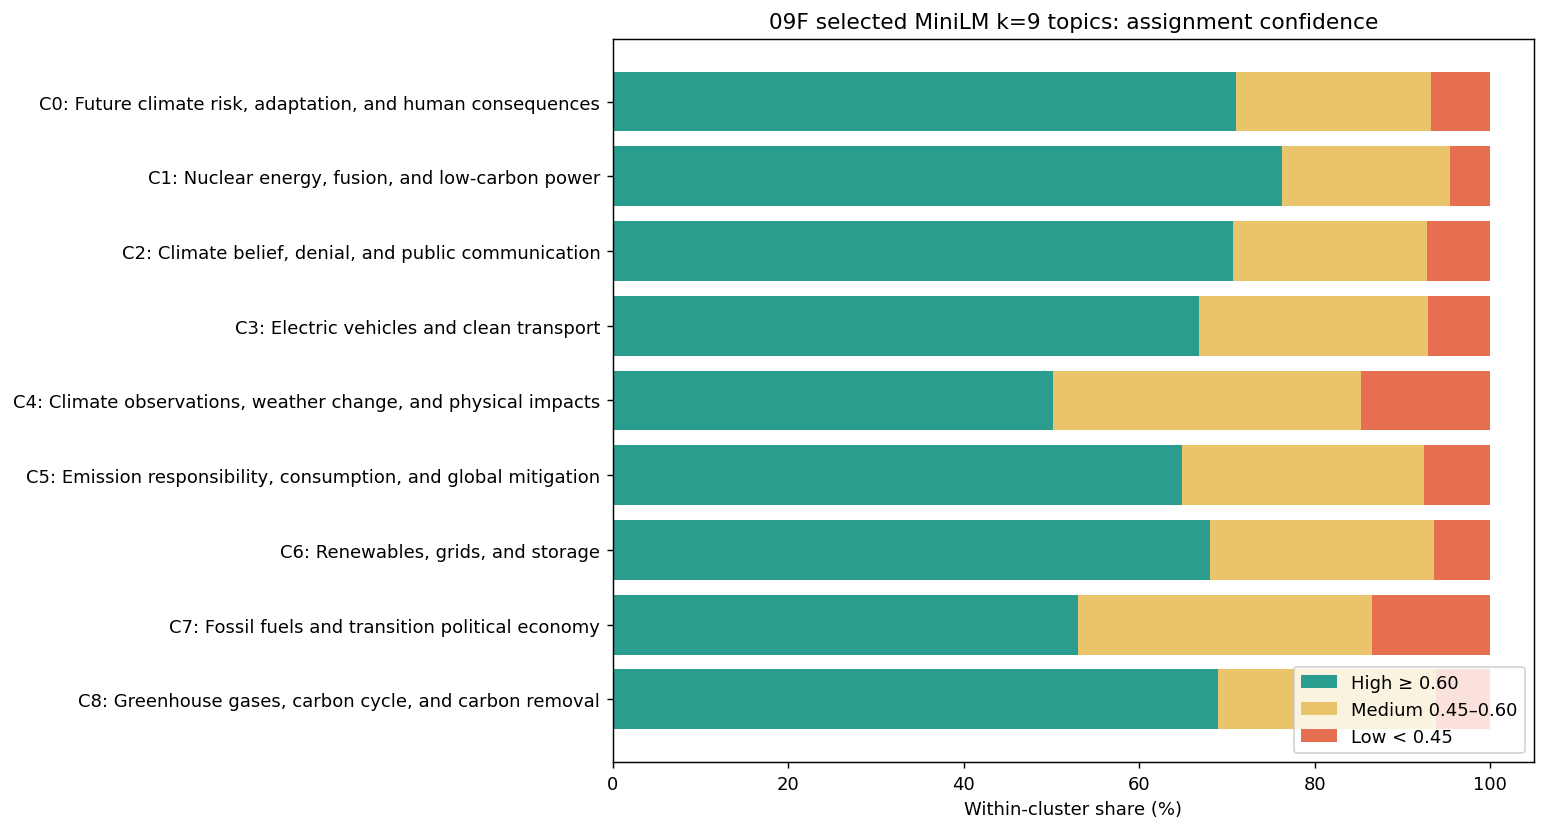

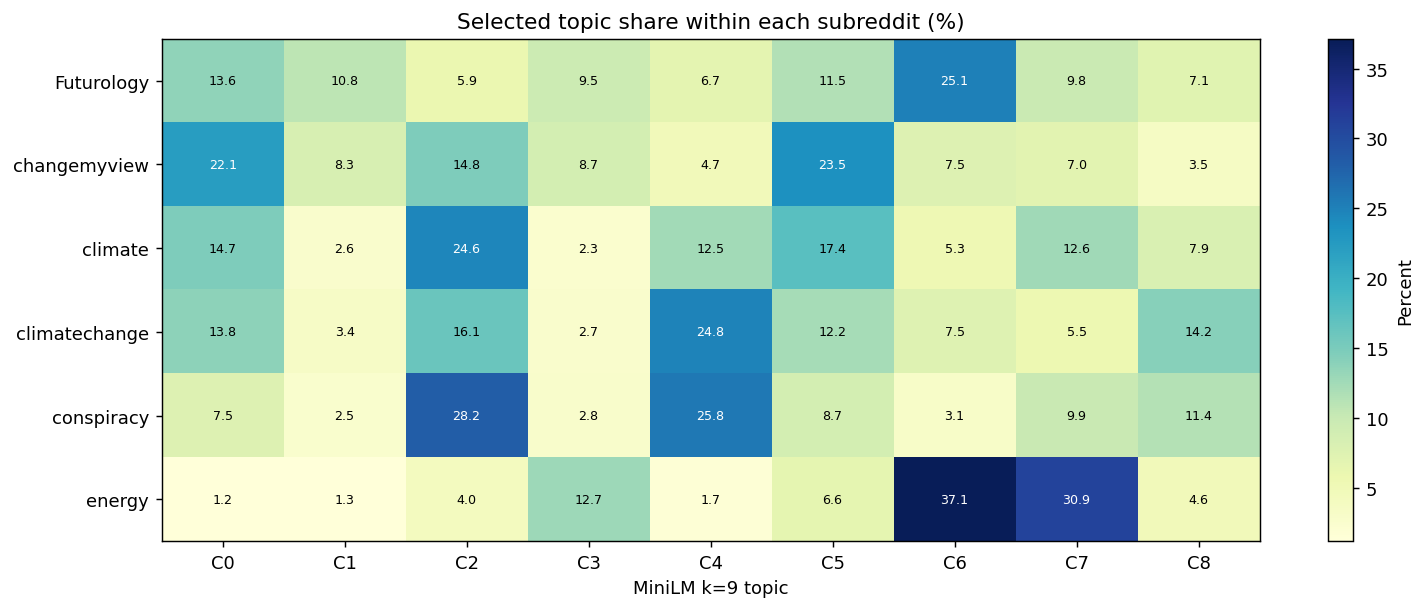

In [9]:
plt.rcParams.update({"figure.dpi": 130, "axes.titlesize": 12, "axes.labelsize": 10})

plot_df = profiles.sort_values("primary_cluster")
labels = [f"C{r.primary_cluster}: {r.topic_name_en}" for r in plot_df.itertuples()]
fig, ax = plt.subplots(figsize=(12, 6.5))
left = np.zeros(len(plot_df))
for column, color, label in [
    ("high_conf_pct", "#2a9d8f", "High ≥ 0.60"),
    ("medium_conf_pct", "#e9c46a", "Medium 0.45–0.60"),
    ("low_conf_pct", "#e76f51", "Low < 0.45"),
]:
    values = plot_df[column].to_numpy()
    ax.barh(labels, values, left=left, color=color, label=label)
    left += values
ax.set_xlabel("Within-cluster share (%)")
ax.set_title("09F selected MiniLM k=9 topics: assignment confidence")
ax.invert_yaxis()
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_topic_confidence.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.8))
image = ax.imshow(community_pct.to_numpy(), aspect="auto", cmap="YlGnBu")
ax.set_yticks(range(len(community_pct.index)), community_pct.index)
ax.set_xticks(range(9), [f"C{i}" for i in range(9)])
ax.set_title("Selected topic share within each subreddit (%)")
ax.set_xlabel("MiniLM k=9 topic")
for i in range(community_pct.shape[0]):
    for j in range(community_pct.shape[1]):
        value = community_pct.iloc[i, j]
        ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=7,
                color="white" if value > 20 else "black")
fig.colorbar(image, ax=ax, label="Percent")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_community_topic_heatmap.png", bbox_inches="tight")
plt.show()

## 9. Export the interpretation layer, judgment evidence, and report conclusion / 导出解释层、判断依据与报告结论

09F never overwrites 09C or 09E. In addition to the interpreted assignment file, it exports a compact one-row-per-topic judgment table and a row-level reading-evidence table containing the centroid and random comments used to interpret each topic. This makes every topic name traceable to both distinctive terms and source text.

09F 不会覆盖 09C 或 09E。除可解释的评论归属文件外，它还导出“一行一个主题”的判断依据表，以及包含各主题中心评论和随机评论的逐行文本证据表，使每个主题名称都能追溯到区分性词语与原始文本。


In [10]:
taxonomy.to_csv(OUTPUT_DIR / "final_topic_taxonomy.csv", index=False, encoding="utf-8-sig")
profiles.to_csv(OUTPUT_DIR / "final_topic_profiles.csv", index=False, encoding="utf-8-sig")
distinctive_terms.to_csv(OUTPUT_DIR / "final_distinctive_terms.csv", index=False, encoding="utf-8-sig")
representative_examples.to_csv(OUTPUT_DIR / "final_representative_examples.csv", index=False, encoding="utf-8-sig")
topic_judgment_basis.to_csv(
    OUTPUT_DIR / "final_topic_judgment_basis.csv", index=False, encoding="utf-8-sig"
)
topic_text_evidence.to_csv(
    OUTPUT_DIR / "final_topic_text_evidence.csv", index=False, encoding="utf-8-sig"
)
review_sample.to_csv(OUTPUT_DIR / "interpretation_review_sample.csv", index=False, encoding="utf-8-sig")
local_split_diagnostics.to_csv(OUTPUT_DIR / "local_split_diagnostics.csv", index=False, encoding="utf-8-sig")
best_local.to_csv(OUTPUT_DIR / "local_split_decisions.csv", index=False, encoding="utf-8-sig")
community_pct.to_csv(OUTPUT_DIR / "community_topic_percentages.csv", encoding="utf-8-sig")
(OUTPUT_DIR / "baseline_advanced_agreement.json").write_text(
    json.dumps(agreement, ensure_ascii=False, indent=2), encoding="utf-8"
)

assignment_columns = [
    "comment_id", "post_id", "subreddit", "created_time", "post_title", "clean_text",
    "review_gate_score", "baseline_selected_k", "baseline_selected_cluster",
    "baseline_selected_membership_strength", "advanced_selected_k", "advanced_selected_cluster",
    "primary_method", "primary_k", "primary_cluster", "primary_membership_strength",
    "topic_name", "topic_name_en", "macro_theme", "macro_theme_en",
    "interpretation_status", "interpretation_note", "interpretation_note_en",
    "confidence_band", "within_cluster_bottom_10pct",
]
df[assignment_columns].to_parquet(OUTPUT_DIR / "09f_interpretable_assignments.parquet", index=False)

clear_n = int(profiles["interpretation_status"].isin(["clear", "clear_with_noise"]).sum())
broad_n = int(profiles["interpretation_status"].eq("broad").sum())
max_local = float(local_split_diagnostics["local_silhouette_cosine"].max())
primary_metrics = decision["advanced_selection"]["metrics"]
baseline_metrics = decision["baseline_selection"]["metrics"]

conclusion = f'''# 09F report-ready clustering conclusion / 09F 可直接用于报告的聚类结论

## 中文

本研究在 09E 中完全使用 09c 的复核驱动门控、平衡样本和 85% 评论 + 15% 上下文表示，独立比较 baseline 与 advanced 的 k=4–20，而不继承旧的 k=12。最终主要模型为 **weighted MiniLM KMeans, k=9**；词汇敏感性基线为 **TF-IDF + LSA KMeans, k=11**。

MiniLM k=9 的语义 silhouette 为 {primary_metrics['silhouette_minilm']:.4f}，五随机种子的平均 ARI 为 {primary_metrics['mean_seed_ari']:.3f}，最小簇占 {primary_metrics['minimum_cluster_share']:.1%}，最大簇占 {primary_metrics['maximum_cluster_share']:.1%}。九个主题中，{clear_n} 个具有清晰或基本清晰的边界，{broad_n} 个使用宽泛名称保留。主题分别覆盖未来风险与人类后果、核能、气候信念与传播、电动车、气候观测与物理影响、减排责任与全球行动、风光储与电网、化石燃料政治经济，以及碳循环与碳移除。

对宽泛主题进行局部 k=2–4 检查后，最高局部 silhouette 为 {max_local:.3f}。局部结果仅作为诊断，任何进一步拆分都必须另做语义复核，不能自动替代九主题方案。归属置信度用于区分核心与边界评论，但不被解释为相关性概率。

基线 k=11 的 LSA silhouette 为 {baseline_metrics['silhouette_lsa']:.4f}，平均种子 ARI 为 {baseline_metrics['mean_seed_ari']:.3f}；但其标签在 MiniLM 空间的 silhouette 仅为 {baseline_metrics['silhouette_minilm']:.4f}。因此 baseline 用于检验结论是否依赖词汇表示，不作为主要语义主题体系。

由于六个社区各抽取 4,705 条评论，社区内部主题比例可以比较，但合并比例不应解释为 Reddit 全体讨论的自然流行率。所有主题名称和解释性判断均为模型辅助复核结果，不是独立人工金标准。

## English

Notebook 09E independently evaluated k=4–20 for both representations using the exact 09c review-informed population and 85% comment + 15% context representation. The selected primary model is **weighted MiniLM KMeans, k=9**, and the lexical sensitivity baseline is **TF-IDF + LSA KMeans, k=11**.

MiniLM k=9 has a semantic silhouette of {primary_metrics['silhouette_minilm']:.4f}, a five-seed mean ARI of {primary_metrics['mean_seed_ari']:.3f}, and cluster shares ranging from {primary_metrics['minimum_cluster_share']:.1%} to {primary_metrics['maximum_cluster_share']:.1%}. {clear_n} topics have clear or mostly clear boundaries and {broad_n} retain deliberately broad labels. The baseline is retained only for lexical sensitivity because its MiniLM-space silhouette is {baseline_metrics['silhouette_minilm']:.4f}.

The modeling sample is balanced across six communities, so within-community topic shares are comparable, while pooled shares are not natural Reddit prevalence estimates. Topic names and interpretation judgments are model-assisted review rather than independent human gold labels.
'''
(OUTPUT_DIR / "report_ready_clustering_conclusion.md").write_text(conclusion, encoding="utf-8")

manifest = {
    "source_notebook": "DM1_09e_review_informed_k_selection.ipynb",
    "primary_model": "weighted all-MiniLM-L6-v2 + KMeans",
    "primary_k": 9,
    "baseline_model": "weighted comment-context TF-IDF + LSA + KMeans",
    "baseline_k": 11,
    "n_modeling_comments": int(len(df)),
    "macro_themes": int(taxonomy["macro_theme"].nunique()),
    "primary_seed_mean_ari": primary_metrics["mean_seed_ari"],
    "interpretation_policy": "retain nine selected topics; use broad labels for clusters 0, 2, and 5; baseline is sensitivity only",
    "files": sorted(p.name for p in OUTPUT_DIR.iterdir()),
}
(OUTPUT_DIR / "run_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)

print(conclusion)
print("Exported to:", OUTPUT_DIR)

# 09F report-ready clustering conclusion / 09F 可直接用于报告的聚类结论

## 中文

本研究在 09E 中完全使用 09c 的复核驱动门控、平衡样本和 85% 评论 + 15% 上下文表示，独立比较 baseline 与 advanced 的 k=4–20，而不继承旧的 k=12。最终主要模型为 **weighted MiniLM KMeans, k=9**；词汇敏感性基线为 **TF-IDF + LSA KMeans, k=11**。

MiniLM k=9 的语义 silhouette 为 0.0705，五随机种子的平均 ARI 为 0.975，最小簇占 4.8%，最大簇占 15.6%。九个主题中，6 个具有清晰或基本清晰的边界，3 个使用宽泛名称保留。主题分别覆盖未来风险与人类后果、核能、气候信念与传播、电动车、气候观测与物理影响、减排责任与全球行动、风光储与电网、化石燃料政治经济，以及碳循环与碳移除。

对宽泛主题进行局部 k=2–4 检查后，最高局部 silhouette 为 0.128。局部结果仅作为诊断，任何进一步拆分都必须另做语义复核，不能自动替代九主题方案。归属置信度用于区分核心与边界评论，但不被解释为相关性概率。

基线 k=11 的 LSA silhouette 为 0.0984，平均种子 ARI 为 0.801；但其标签在 MiniLM 空间的 silhouette 仅为 0.0009。因此 baseline 用于检验结论是否依赖词汇表示，不作为主要语义主题体系。

由于六个社区各抽取 4,705 条评论，社区内部主题比例可以比较，但合并比例不应解释为 Reddit 全体讨论的自然流行率。所有主题名称和解释性判断均为模型辅助复核结果，不是独立人工金标准。

## English

Notebook 09E independently evaluated k=4–20 for both representations using the exact 09c review-informed population and 85% comment + 15% context representation. The selected primary model is **weighted MiniLM 

## Final usage rules / 最终使用规则

1. Run Notebook 09E from top to bottom first; it produces the selected k=9 primary assignments and k=11 lexical baseline.
2. Run this Notebook 09F from top to bottom. All interpretation, checks, figures, and exports are produced by its own cells; no external Python script is required.
3. Use `primary_cluster` and `topic_name` from MiniLM k=9 for the main analysis.
4. Use `macro_theme` only when broader aggregation is analytically justified.
5. Treat `confidence_band` as relative assignment strength, not as a probability that a comment is relevant.
6. Use the TF-IDF/LSA k=11 result only as a representation-sensitivity baseline.
7. Because the sample contains exactly 4,705 comments from each community, compare percentages within communities; do not interpret pooled percentages as natural Reddit prevalence.

---

1. 先从头到尾运行 09E；它会生成主要 MiniLM k=9 与词汇基线 k=11 的最终归属。
2. 再从头到尾运行本 09F。解释、检验、图形和导出全部由 Notebook 自身单元格完成，不需要外部 Python 脚本。
3. 主分析使用 MiniLM k=9 的 `primary_cluster` 与 `topic_name`。
4. 只有在研究问题确实需要更高层聚合时才使用 `macro_theme`。
5. `confidence_band` 表示相对归属强度，不是“评论相关”的概率。
6. TF-IDF/LSA k=11 仅作为表示敏感性基线。
7. 六个社区各有 4,705 条评论，因此可比较社区内部比例；合并比例不能解释为 Reddit 的自然流行率。
